MAE: 2.85 | RMSE: 3.58


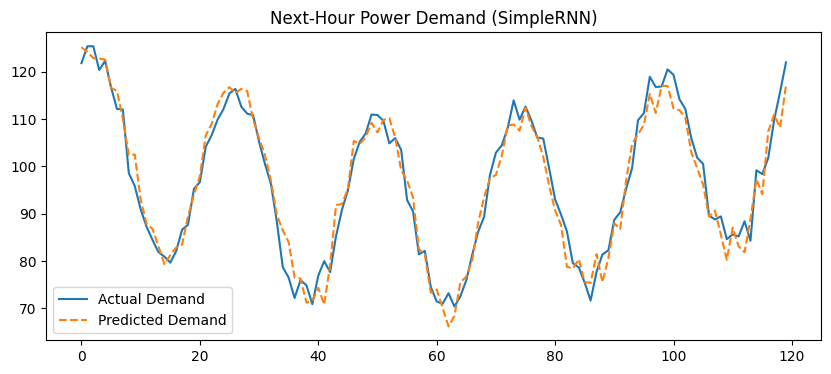

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from tensorflow.keras import layers, models

t = np.arange(1500)
demand = 100 + 20*np.sin(2*np.pi*t/24) + 10*np.cos(2*np.pi*t/168) + np.random.normal(0, 2, size=len(t))
series = pd.Series(demand).interpolate().values.reshape(-1, 1)

scaler = MinMaxScaler()
scaled = scaler.fit_transform(series)

win = 24
X, y = [], []
for i in range(len(scaled) - win):
    X.append(scaled[i:i+win]); y.append(scaled[i+win])
X, y = np.array(X), np.array(y)

split = int(0.8 * len(X))
X_tr, X_te, y_tr, y_te = X[:split], X[split:], y[:split], y[split:]

model = models.Sequential([
    layers.Input(shape=(win, 1)),
    layers.SimpleRNN(32, activation="tanh"),
    layers.Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.fit(X_tr, y_tr, epochs=10, batch_size=32, verbose=0)

pred = scaler.inverse_transform(model.predict(X_te, verbose=0))
actual = scaler.inverse_transform(y_te)
print(f"MAE: {mean_absolute_error(actual, pred):.2f} | RMSE: {root_mean_squared_error(actual, pred):.2f}")

plt.figure(figsize=(10, 4))
plt.plot(actual[:120], label="Actual Demand")
plt.plot(pred[:120], label="Predicted Demand", linestyle="--")
plt.title("Next-Hour Power Demand (SimpleRNN)"); plt.legend(); plt.show()